# K-Means initialization strategies on the digits data: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/cluster/plot_kmeans_digits.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/cluster/plot_kmeans_digits.html)).

**Scenario:** bundled digits (1797 x 64, offline). Three `KMeans(n_clusters=10)` initialisations
(`"k-means++"`, `n_init=4`, `random_state=0`; `"random"`, `n_init=4`, `random_state=0`; and the
`PCA(n_components=10).components_` array, `n_init=1`) run after `StandardScaler`, then
`KMeans("k-means++", n_init=4, random_state=42)` clusters 2-D PCA-reduced data and its `predict`
draws the decision regions. Beyond the example: `transform`, `score`, `get_feature_names_out`,
`algorithm="elkan"`, Float32, `clone` + `set_params` refit, `k_means` and `kmeans_plusplus`.

**Adaptations:**
- `make_pipeline(StandardScaler(), kmeans)` cannot be built in Moxie (its pipeline requires a supervised
  predictor as final step; see the expect-fail cell). The Moxie cells chain `StandardScaler.fit_transform`
  and `KMeans.fit` by hand, which is what the pipeline does.
- The clustering metrics (homogeneity, ..., silhouette) are computed in Python from the labels of both
  implementations: Moxie has no `metrics` module yet. The example's silhouette uses `sample_size=300`
  without a seed; here `random_state=0` is added so both rows use the same subsample.
- The decision-region grid uses `grid_resolution=200` instead of 1000 (40k instead of 1M predictions)
  to keep the notebook small; the plot is otherwise the same.
- Fit times are reported but not compared.

**Determinism:** with fixed seeds the reference is deterministic. Moxie's `RandomState` reproduces
NumPy's MT19937 stream and sklearn's sampling calls (documented in `algorithms/kmeans/docs/api.md`),
so seeded initialisations, labels and iteration counts are compared exactly; centers and inertia
numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("cluster/plot_kmeans_digits")

## 1. scikit-learn (Python reference)

In [2]:
import numpy as np
from sklearn.datasets import load_digits

data, labels = load_digits(return_X_y=True)
(n_samples, n_features), n_digits = data.shape, np.unique(labels).size

print(f"# digits: {n_digits}; # samples: {n_samples}; # features {n_features}")

from time import time

from sklearn import metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def cluster_scores(data, pred):
    clustering_metrics = [
        metrics.homogeneity_score,
        metrics.completeness_score,
        metrics.v_measure_score,
        metrics.adjusted_rand_score,
        metrics.adjusted_mutual_info_score,
    ]
    results = [m(labels, pred) for m in clustering_metrics]
    results += [metrics.silhouette_score(data, pred, metric="euclidean", sample_size=300, random_state=0)]
    return results


def bench_k_means(kmeans, name, data, labels):
    t0 = time()
    estimator = make_pipeline(StandardScaler(), kmeans).fit(data)
    fit_time = time() - t0
    results = [name, fit_time, estimator[-1].inertia_] + cluster_scores(data, estimator[-1].labels_)
    formatter_result = (
        "{:9s}\t{:.3f}s\t{:.0f}\t{:.3f}\t{:.3f}\t{:.3f}\t{:.3f}\t{:.3f}\t{:.3f}"
    )
    print(formatter_result.format(*results))
    return estimator


from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

print(82 * "_")
print("init\t\ttime\tinertia\thomo\tcompl\tv-meas\tARI\tAMI\tsilhouette")
kmeans = KMeans(init="k-means++", n_clusters=n_digits, n_init=4, random_state=0)
sk_pp = bench_k_means(kmeans=kmeans, name="k-means++", data=data, labels=labels)

kmeans = KMeans(init="random", n_clusters=n_digits, n_init=4, random_state=0)
sk_rand = bench_k_means(kmeans=kmeans, name="random", data=data, labels=labels)

pca = PCA(n_components=n_digits).fit(data)
kmeans = KMeans(init=pca.components_, n_clusters=n_digits, n_init=1)
sk_pca = bench_k_means(kmeans=kmeans, name="PCA-based", data=data, labels=labels)

print(82 * "_")

# digits: 10; # samples: 1797; # features 64
__________________________________________________________________________________
init		time	inertia	homo	compl	v-meas	ARI	AMI	silhouette
k-means++	0.074s	69545	0.598	0.645	0.621	0.469	0.617	0.156


random   	0.099s	69735	0.681	0.723	0.701	0.574	0.698	0.174
PCA-based	0.090s	69513	0.600	0.647	0.622	0.468	0.618	0.157
__________________________________________________________________________________


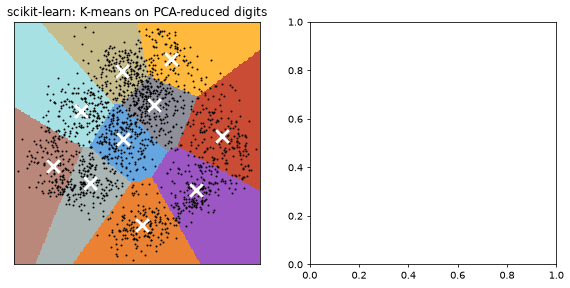

In [3]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

reduced_data = PCA(n_components=2).fit_transform(data)
kmeans = KMeans(init="k-means++", n_clusters=n_digits, n_init=4, random_state=42)
kmeans.fit(reduced_data)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=70)
disp = DecisionBoundaryDisplay.from_estimator(
    kmeans, reduced_data, ax=axes[0], response_method="predict", alpha=0.8,
    plot_method="pcolormesh", grid_resolution=200,
)
axes[0].plot(reduced_data[:, 0], reduced_data[:, 1], "k.", markersize=2)
centroids = kmeans.cluster_centers_
axes[0].scatter(centroids[:, 0], centroids[:, 1], marker="x", s=169, linewidths=3, color="w", zorder=10)
axes[0].set_title("scikit-learn: K-means on PCA-reduced digits")
axes[0].set_xticks(()); axes[0].set_yticks(())
grid = np.c_[disp.xx0.ravel(), disp.xx1.ravel()]
sk_grid_pred = kmeans.predict(grid)

# Beyond the example
scaled = StandardScaler().fit_transform(data)
sk_elkan = KMeans(n_clusters=n_digits, n_init=4, random_state=0, algorithm="elkan").fit(scaled)
sk_32 = KMeans(n_clusters=n_digits, n_init=4, random_state=0).fit(scaled.astype(np.float32))
from sklearn.base import clone
sk_clone = clone(sk_pp[-1]).set_params(n_clusters=5, init="random").fit(scaled)
from sklearn.cluster import k_means, kmeans_plusplus
km_centers, km_labels, km_inertia, km_iter = k_means(scaled, n_digits, n_init=2, random_state=3, return_n_iter=True)
pp_centers, pp_indices = kmeans_plusplus(scaled, n_digits, random_state=7)
nb.share(data=data, reduced=reduced_data, grid=grid, pca_components=pca.components_,
         scaled32=scaled.astype(np.float32))

## 2. Moxie (native Mojo)

StandardScaler, PCA and every KMeans fit/predict run in Mojo. Python only supplies the digits,
the 2-D reduced data and the decision grid (the reduced data are shared rather than recomputed so
the second part tests KMeans alone; Moxie's own PCA is compared separately).

In [4]:
%%mojo kmeans_digits
from moxie.base import clone
from moxie.cluster import KMeans, k_means, kmeans_plusplus
from moxie.cluster._kmeans import KMeansInit
from moxie.decomposition import PCA
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load, save, save_floats, save_ints, save_strings
from std.time import perf_counter_ns


def main() raises:
    var data = load("data")
    var inertias = List[Float64]()
    var n_iters = List[Int]()

    var scaler = StandardScaler()
    var scaled = scaler.fit_transform(data)

    var t0 = perf_counter_ns()
    var pp = KMeans(10, init="k-means++", n_init=4, random_state=0)
    _ = pp.fit(scaled)
    print("k-means++ fit:", Float64(perf_counter_ns() - t0) / 1e9, "s, inertia", pp.inertia_)
    save("pp_labels", pp.labels_); save("pp_centers", pp.cluster_centers_)
    inertias.append(pp.inertia_); n_iters.append(pp.n_iter_)

    t0 = perf_counter_ns()
    var rand = KMeans(10, init="random", n_init=4, random_state=0)
    _ = rand.fit(scaled)
    print("random fit:", Float64(perf_counter_ns() - t0) / 1e9, "s, inertia", rand.inertia_)
    save("rand_labels", rand.labels_); save("rand_centers", rand.cluster_centers_)
    inertias.append(rand.inertia_); n_iters.append(rand.n_iter_)

    var pca = PCA(n_components=10)
    _ = pca.fit(data)
    var components = pca.components_.value().copy()
    save("pca_components", components)
    # The PCA init uses the reference's components so this row isolates KMeans; Moxie's
    # own PCA components are compared separately above.
    var pca_init = KMeans(10, init=KMeansInit[DType.float64](load("pca_components")), n_init=1)
    _ = pca_init.fit(scaled)
    save("pca_labels", pca_init.labels_); save("pca_centers", pca_init.cluster_centers_)
    inertias.append(pca_init.inertia_); n_iters.append(pca_init.n_iter_)

    var reduced = load("reduced")
    var km2 = KMeans(10, init="k-means++", n_init=4, random_state=42)
    _ = km2.fit(reduced)
    save("reduced_centers", km2.cluster_centers_)
    save("grid_pred", km2.predict(load("grid")))
    save("reduced_transform", km2.transform(reduced))
    var scores = List[Float64]()
    scores.append(km2.score(reduced))
    save_strings("feature_names", km2.get_feature_names_out())

    var elkan = KMeans(10, n_init=4, random_state=0, algorithm="elkan")
    _ = elkan.fit(scaled)
    save("elkan_labels", elkan.labels_); inertias.append(elkan.inertia_); n_iters.append(elkan.n_iter_)
    var km32 = KMeans[DType.float32](10, n_init=4, random_state=0)
    _ = km32.fit(load[DType.float32]("scaled32"))
    save("f32_labels", km32.labels_); save("f32_centers", km32.cluster_centers_)
    var cl = clone(pp)
    _ = cl.set_params(n_clusters=5, init=KMeansInit[DType.float64]("random"))
    _ = cl.fit(scaled)
    save("clone_labels", cl.labels_); inertias.append(cl.inertia_)
    var res = k_means(scaled, 10, n_init=2, random_state=3, return_n_iter=True)
    save("k_means_labels", res.labels); save("k_means_centers", res.centers)
    inertias.append(res.inertia); n_iters.append(res.n_iter.value())
    var seeds = kmeans_plusplus(scaled, 10, random_state=7)
    save("pp_indices", seeds.indices)
    save_floats("inertias", inertias); save_ints("n_iters", n_iters); save_floats("scores", scores)

k-means++ fit: 2.041212925 s, inertia 69545.33156153974
random fit: 3.372529899 s, inertia 69735.37802110358


## 3. Side by side and parity

,init,impl,inertia,homo,compl,v-meas,ARI,AMI,silhouette
0,k-means++,sklearn,69545.332,0.598,0.645,0.621,0.469,0.617,0.156
1,k-means++,moxie,69545.332,0.598,0.645,0.621,0.469,0.617,0.156
2,random,sklearn,69735.378,0.681,0.723,0.701,0.574,0.698,0.174
3,random,moxie,69735.378,0.681,0.723,0.701,0.574,0.698,0.174
4,PCA-based,sklearn,69513.441,0.600,0.647,0.622,0.468,0.618,0.157
5,PCA-based,moxie,69513.441,0.600,0.647,0.622,0.468,0.618,0.157


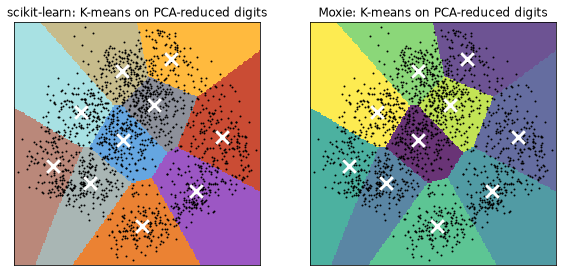

In [5]:
mx = nb.results["kmeans_digits"]
rows = []
for name, est, key, inertia in (("k-means++", sk_pp, "pp", mx["inertias"][0]),
                                 ("random", sk_rand, "rand", mx["inertias"][1]),
                                 ("PCA-based", sk_pca, "pca", mx["inertias"][2])):
    rows.append([name, "sklearn", est[-1].inertia_, *cluster_scores(data, est[-1].labels_)])
    rows.append([name, "moxie", inertia, *cluster_scores(data, mx[f"{key}_labels"])])
import pandas as pd
display(pd.DataFrame(rows, columns=["init", "impl", "inertia", "homo", "compl", "v-meas", "ARI", "AMI", "silhouette"]).round(3))

fig = disp.figure_
axes[1].pcolormesh(disp.xx0, disp.xx1, mx["grid_pred"].reshape(disp.xx0.shape), alpha=0.8, shading="auto")
axes[1].plot(reduced_data[:, 0], reduced_data[:, 1], "k.", markersize=2)
c = mx["reduced_centers"]
axes[1].scatter(c[:, 0], c[:, 1], marker="x", s=169, linewidths=3, color="w", zorder=10)
axes[1].set_title("Moxie: K-means on PCA-reduced digits"); axes[1].set_xticks(()); axes[1].set_yticks(())
display(fig)

center_reason = ("Float64 Lloyd updates; Moxie's native reductions and sklearn's BLAS/Cython sums "
                 "differ in the last bits (rtol/atol of algorithms/kmeans/docs/api.md)")
for name, est, key in (("k-means++", sk_pp, "pp"), ("random", sk_rand, "rand"), ("PCA-based", sk_pca, "pca")):
    nb.compare(f"{name} labels_", est[-1].labels_, mx[f"{key}_labels"], exact=True)
    nb.compare(f"{name} cluster_centers_", est[-1].cluster_centers_, mx[f"{key}_centers"],
               rtol=2e-12, atol=2e-13, reason=center_reason)
sk_inertias = [sk_pp[-1].inertia_, sk_rand[-1].inertia_, sk_pca[-1].inertia_, sk_elkan.inertia_,
               sk_clone.inertia_, km_inertia]
nb.compare("inertia_ (pp, random, PCA, elkan, clone, k_means)", sk_inertias, mx["inertias"],
           rtol=2e-12, reason=center_reason)
nb.compare("n_iter_ (pp, random, PCA, elkan, k_means)",
           [sk_pp[-1].n_iter_, sk_rand[-1].n_iter_, sk_pca[-1].n_iter_, sk_elkan.n_iter_, km_iter],
           mx["n_iters"], exact=True)
nb.compare("PCA(10).components_ (Moxie PCA)", pca.components_, mx["pca_components"], rtol=1e-9, atol=1e-11,
           reason="full SVD from LAPACK vs Moxie's solver; same svd_flip sign convention")
nb.compare("reduced-data cluster_centers_", kmeans.cluster_centers_, mx["reduced_centers"], rtol=2e-12, atol=2e-13, reason=center_reason)
nb.compare("predict on 200x200 grid", sk_grid_pred, mx["grid_pred"], exact=True)
nb.compare("transform", kmeans.transform(reduced_data), mx["reduced_transform"], rtol=1e-12, atol=1e-12,
           reason="Moxie uses direct coordinate differences, sklearn the norm/dot expansion")
nb.compare("score", kmeans.score(reduced_data), mx["scores"][0], rtol=1e-12, reason=center_reason)
nb.compare("get_feature_names_out", kmeans.get_feature_names_out(), mx["feature_names"], exact=True)
nb.compare("elkan labels_", sk_elkan.labels_, mx["elkan_labels"], exact=True)
nb.compare("Float32 labels_", sk_32.labels_, mx["f32_labels"], exact=True)
nb.compare("Float32 cluster_centers_", sk_32.cluster_centers_, mx["f32_centers"], rtol=4e-5, atol=3e-6,
           reason="Float32 accumulation order (documented Float32 tolerance in algorithms/kmeans/docs/api.md)")
nb.compare("clone + set_params(5, random) refit labels_", sk_clone.labels_, mx["clone_labels"], exact=True)
nb.compare("k_means labels", km_labels, mx["k_means_labels"], exact=True)
nb.compare("k_means centers", km_centers, mx["k_means_centers"], rtol=2e-12, atol=2e-13, reason=center_reason)
nb.compare("kmeans_plusplus indices", pp_indices, mx["pp_indices"], exact=True);

### Composition: KMeans as a transformer inside `moxie.pipeline`

Beyond the example: the sklearn idioms `make_pipeline(KMeans(...), NearestCentroid())` (cluster distances as
features for a classifier) and `make_union(StandardScaler(), KMeans(...))` (scaled features next to
cluster distances). KMeans can be an intermediate step because it is a `TransformerMixin`.

In [6]:
from sklearn.neighbors import NearestCentroid
from sklearn.pipeline import make_union
sk_pipe = make_pipeline(KMeans(n_clusters=n_digits, n_init=4, random_state=0), NearestCentroid()).fit(scaled, labels)
sk_pipe_pred = sk_pipe.predict(scaled)
sk_union = make_union(StandardScaler(), KMeans(n_clusters=n_digits, n_init=4, random_state=0)).fit_transform(data)
print("pipeline training accuracy:", (sk_pipe_pred == labels).mean(), "union shape:", sk_union.shape)
nb.share(scaled=scaled, labels=labels.astype(np.float64))

pipeline training accuracy: 0.5948803561491375 union shape: (1797, 74)


In [7]:
%%mojo kmeans_composition
from moxie.cluster import KMeans
from moxie.neighbors import NearestCentroid
from moxie.pipeline import make_pipeline, make_union
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load, save


def main() raises:
    var scaled = load("scaled")
    var y = load("labels")
    # Labels travel as Float64 NDArray, NearestCentroid's default label domain.
    var pipe = make_pipeline(KMeans(10, n_init=4, random_state=0), NearestCentroid())
    _ = pipe.fit(scaled, y)
    save("pipe_pred", pipe.predict(scaled))
    var union = make_union(StandardScaler(), KMeans(10, n_init=4, random_state=0))
    save("union", union.fit_transform(load("data")))

In [8]:
mc = nb.results["kmeans_composition"]
nb.compare("make_pipeline(KMeans, NearestCentroid).predict", sk_pipe_pred, mc["pipe_pred"], exact=True)
nb.compare("make_union(StandardScaler, KMeans).fit_transform", sk_union, mc["union"], rtol=1e-11, atol=1e-11,
           reason="scaled features and Euclidean distances to Float64 centers; summation order differs");

### The example's pipeline

`make_pipeline(StandardScaler(), KMeans(...))` is the example's composition. Moxie's
`make_pipeline` requires the final step to be a supervised predictor, so the call does not compile.

In [9]:
%%mojo kmeans_pipeline --expect-fail
from moxie.cluster import KMeans
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load


def main() raises:
    var pipe = make_pipeline(StandardScaler(), KMeans(10, n_init=4, random_state=0))
    _ = pipe.fit(load("data"))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/cluster/plot_kmeans_digits/kmeans_pipeline.mojo:8:54: error: invalid call to 'make_pipeline': value passed to 'estimator' cannot be converted from 'KMeans' to 'E', argument type 'KMeans' does not conform to trait 'Predictor & SupervisedEstimator & Deinitable'
    var pipe = make_pipeline(StandardScaler(), KMeans(10, n_init=4, random_state=0))
               ~~~~~~~~~~~~~                   ~~~~~~^~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/cluster/plot_kmeans_digits/kmeans_pipeline.mojo:2:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_pipeline_api.mojo:39:5: note: function declared here
def make_pipeline[P: TransformerMixin & Deinita

In [10]:
nb.note("make_pipeline(StandardScaler(), KMeans)", "GAP",
        "Moxie Pipeline needs a SupervisedEstimator & Predictor final step; clusterers cannot end a "
        "pipeline (same root cause as #21 part 1 / #24 part 1). Chained by hand above.")
nb.note("make_pipeline(KMeans, GaussianNB)", "GAP",
        "Moxie GaussianNB takes a List-based _Matrix, KMeans.transform returns NDArray; the shared Pipeline "
        "rebinds without a type check and fails to compile with a raw rebind error (_pipeline_sequential.mojo:176). "
        "NearestCentroid (NDArray input) is used instead.")
nb.note("GridSearchCV / cross_val_score over KMeans", "GAP",
        "moxie.model_selection has no generic unsupervised estimator.score adapter (#3 part 3); not exercised here")
nb.note("sklearn.metrics clustering scores", "ADAPTED",
        "no moxie.metrics yet; scores computed in Python from both implementations' labels")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
k-means++ labels_,PASS,"(1797,)","(1797,)",,,exact,0 mismatches,
k-means++ cluster_centers_,PASS,"(10, 64)","(10, 64)",5.11e-15,1.1e-13,"rtol=2e-12, atol=2e-13",,Float64 Lloyd updates; Moxie's native reductions and sklearn's BLAS/Cython sums differ in the last bits (rtol/atol of algorithms/kmeans/docs/api.md)
random labels_,PASS,"(1797,)","(1797,)",,,exact,0 mismatches,
random cluster_centers_,PASS,"(10, 64)","(10, 64)",5.11e-15,3.63e-14,"rtol=2e-12, atol=2e-13",,Float64 Lloyd updates; Moxie's native reductions and sklearn's BLAS/Cython sums differ in the last bits (rtol/atol of algorithms/kmeans/docs/api.md)
PCA-based labels_,PASS,"(1797,)","(1797,)",,,exact,0 mismatches,
PCA-based cluster_centers_,PASS,"(10, 64)","(10, 64)",5.33e-15,3.01e-14,"rtol=2e-12, atol=2e-13",,Float64 Lloyd updates; Moxie's native reductions and sklearn's BLAS/Cython sums differ in the last bits (rtol/atol of algorithms/kmeans/docs/api.md)
"inertia_ (pp, random, PCA, elkan, clone, k_means)",PASS,"(6,)","(6,)",2.47e-10,3.55e-15,"rtol=2e-12, atol=0",,Float64 Lloyd updates; Moxie's native reductions and sklearn's BLAS/Cython sums differ in the last bits (rtol/atol of algorithms/kmeans/docs/api.md)
"n_iter_ (pp, random, PCA, elkan, k_means)",PASS,"(5,)","(5,)",,,exact,0 mismatches,
PCA(10).components_ (Moxie PCA),PASS,"(10, 64)","(10, 64)",4.33e-15,1,"rtol=1e-09, atol=1e-11",,full SVD from LAPACK vs Moxie's solver; same svd_flip sign convention
reduced-data cluster_centers_,PASS,"(10, 2)","(10, 2)",1.07e-14,7.58e-16,"rtol=2e-12, atol=2e-13",,Float64 Lloyd updates; Moxie's native reductions and sklearn's BLAS/Cython sums differ in the last bits (rtol/atol of algorithms/kmeans/docs/api.md)
